<a href="https://colab.research.google.com/github/preethikamanokaran/Titanic-Survival-Prediction/blob/main/Titanic_Survival_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:

data = df[[
    "survived", "pclass", "sex", "age",
    "sibsp", "parch", "fare", "embarked"
]].copy()

data["age"] = data["age"].fillna(data["age"].median())
data["embarked"] = data["embarked"].fillna(
    data["embarked"].mode()[0]
)

data = pd.get_dummies(
    data, columns=["sex", "embarked"], dtype=int
)

print("Data prepared successfully!")
print("Missing values:", data.isnull().sum().sum())

data.head()

Data prepared successfully!
Missing values: 0


,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,0,1,0,0,1


In [4]:

X = data.drop("survived", axis=1)
y = data["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Model trained successfully!")
print("Model accuracy:", round(accuracy * 100, 2), "%")

Model trained successfully!
Model accuracy: 82.12 %


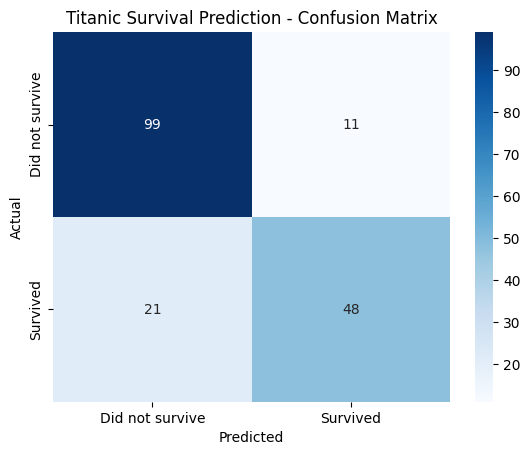

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [5]:

cm = confusion_matrix(y_test, predictions)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Did not survive", "Survived"],
    yticklabels=["Did not survive", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.show()

print(classification_report(y_test, predictions))

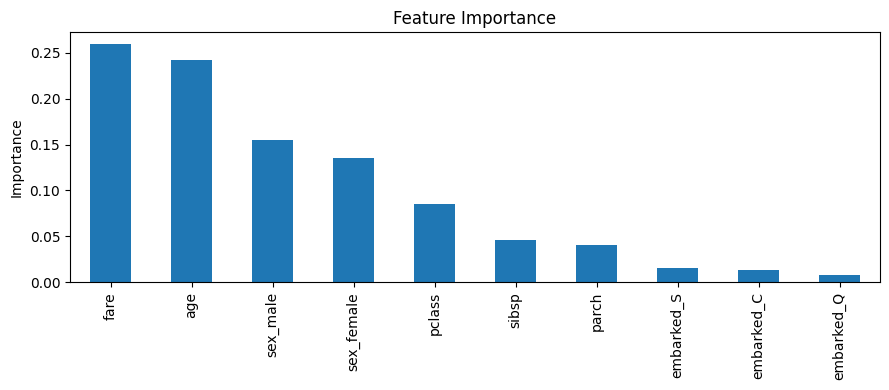

In [6]:

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.plot(kind="bar", figsize=(9, 4))
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [7]:

print("""
CONCLUSION

A Random Forest machine-learning model was trained
to predict Titanic passenger survival.

The dataset was prepared, divided into training and
testing sets, and evaluated using accuracy,
a confusion matrix, and a classification report.

Feature importance was visualized to understand
which passenger details influenced predictions.

This project demonstrates supervised machine learning
and model evaluation using Python.
""")


CONCLUSION

A Random Forest machine-learning model was trained
to predict Titanic passenger survival.

The dataset was prepared, divided into training and
testing sets, and evaluated using accuracy,
a confusion matrix, and a classification report.

Feature importance was visualized to understand
which passenger details influenced predictions.

This project demonstrates supervised machine learning
and model evaluation using Python.

